In [0]:
import pandas as pd

data = pd.read_csv("wall and bed.csv")

In [0]:
#Data Cleaning

data = data.iloc[1:].reset_index(drop=True)
data = data[['v_drift', 'h_drift', 'Angle1']]
data.columns = ['pan', 'tilt', 'Distance_mm']
data['pan'] = data['pan'].astype(float)
data['tilt'] = data['tilt'].astype(float)
data['Distance_mm'] = data['Distance_mm'].astype(float)

pan,tilt,Distance_mm
90.0,0.0,-1.0
91.0,0.0,-1.0
92.0,0.0,-1.0
93.0,0.0,-1.0
94.0,0.0,-1.0


In [0]:
# PHI Adjusted
v_drift_bottom = 45
data["phi_tilt"] =  v_drift_bottom - pd.to_numeric(data["tilt"], errors='coerce')

# THETA Adjusted
h_drift_bottom = 90
data["theta_pan"] = pd.to_numeric(data["pan"],errors = 'coerce') - h_drift_bottom 

In [0]:
import numpy as np

data = data[(data['Distance_mm'] > -1) & (data['Distance_mm'] < 2000)]  
data["Z"] = data["Distance_mm"]*np.sin(np.radians(data['phi_tilt']))
data["X"] = data["Distance_mm"]*np.cos(np.radians(data['phi_tilt']))*np.cos(np.radians(data["theta_pan"]))
data["Y"] = data["Distance_mm"]*np.cos(np.radians(data['phi_tilt']))*np.sin(np.radians(data["theta_pan"]))

In [0]:
data["Distance_mm"].unique()

array([1152., 1129., 1177., 1171., 1181., 1189., 1188., 1170., 1190.,
       1221., 1187., 1178., 1204., 1197., 1217., 1228., 1216., 1220.,
       1231., 1248., 1253., 1247.,  162.,  287.,   53.,  195.,  417.,
        462.,  526.,  510.,  509.,  549.,  598.,  574.,  520.,  523.,
        587.,  590.,  655.,  672.,  586.,  543.,  671.,  623.,  609.,
        632.,  612.,  643.,  618.,  601.,  583.,  580.,  566.,  554.,
        561.,  514.,  529.,  506.,  513.,  503.,  485.,  466.,  474.,
        488.,  500.,  476.,  470.,  447.,  486.,  531.,  532.,  551.,
        691., 1252., 1245., 1222., 1226., 1223., 1203., 1192., 1180.,
       1158., 1155., 1166., 1156., 1138., 1145., 1148., 1136., 1134.,
       1125., 1124., 1123., 1087., 1100., 1074., 1086., 1068., 1055.,
       1062., 1053., 1050.,  713.,  708.,  752.,  849.,  853.,  901.,
        938.,  996., 1025., 1013., 1067., 1045., 1080., 1083., 1097.,
       1101., 1094., 1126., 1096., 1131., 1122., 1135., 1140., 1142.,
       1160., 1164.,

In [0]:
!pip install open3d
import open3d as draw
point_cloud = draw.geometry.PointCloud()
xyz = data[["X","Y","Z"]].to_numpy()
point_cloud.points = draw.utility.Vector3dVector(xyz)
#draw.visualization.draw_geometries([point_cloud])

In [0]:
draw.io.write_point_cloud('/Workspace/Users/rathoremehul07@gmail.com/Drafts/lidar_point_cloud_wallandbed.ply', point_cloud)

True

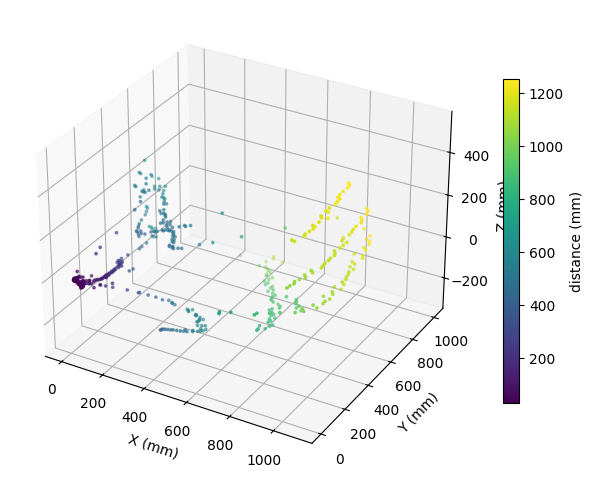

In [0]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection='3d')

# Pass X, Y, and Z as three separate arguments, not one grouped 'xyz' variable
p = ax.scatter(data["X"], data["Y"], data["Z"], c=data["Distance_mm"], s=3, cmap='viridis')

fig.colorbar(p, label='distance (mm)', shrink=0.7)
ax.set_xlabel('X (mm)')
ax.set_ylabel('Y (mm)')
ax.set_zlabel('Z (mm)')

# Use data["X"] instead of xyz["X"] to avoid indexing errors
ax.set_box_aspect((max(np.ptp(data["X"]), 1), max(np.ptp(data["Y"]), 1), max(np.ptp(data["Z"]), 1)))  

plt.show()